# Step 2: Can walking patterns tell Almaty from SF?

Input: `data/daily_hourly.csv` (made at the end of notebook 1). One row per day with 24 hourly step counts, a city label and the period (stretch of time) the day belongs to.

Comparison conditions:
1. Majority-class baseline
2. Logistic regression on summary features
3. Logistic regression on the hourly step fractions
4. Random forest on the hourly step counts

Two ways of splitting the data:
- **Random 5-fold CV:** neighbouring days from the same stretch land in train and test.
- **Held-out periods:** each fold holds out one whole Almaty period and one whole SF period, so the model is tested on stretches it never saw.

In [2]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, learning_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
HOUR_COLS = [f'h{h:02d}' for h in range(24)]

df = pd.read_csv('data/daily_hourly.csv', parse_dates=['date'])
df['y'] = (df['city'] == 'Almaty').astype(int)   # 1 = Almaty, 0 = SF
print(df['city'].value_counts())
print(df.groupby(['city', 'period']).size())

city
Almaty    643
SF        468
Name: count, dtype: int64
city    period
Almaty  ALM1      408
        ALM2      120
        ALM3       27
        ALM4       88
SF      SF1       231
        SF2        77
        SF3       121
        SF4        39
dtype: int64


## Features

For each day, we look at how steps are spread across the 24 hours. We use a measure called step entropy to understand whether someone walks mostly during certain times or throughout the day. 

- Low step entropy: Most steps happen during a few hours, such as walking to work or going on one long walk. 

- High step entropy: Steps are spread more evenly throughout the day, meaning the person walks at different times. We calculate step entropy using:

$$H_d = -\sum_{h=0}^{23} p_h \log p_h$$

Here, $p_h$ represents the percentage of the day's total steps taken during a specific hour.

Summary features: total steps, peak hour, first and last active hour (hours with at least 50 steps), number of active hours, and $H_d$.

In [ ]:
def build_features(frame, active_threshold=50):
    # Get the step counts for each hour of the day
    counts = frame[HOUR_COLS].to_numpy(float)

    # Calculate the total number of steps for each day
    total = counts.sum(axis=1)

    # Calculate what fraction of daily steps happened each hour
    frac = counts / total[:, None]

    # Replace zero fractions with 1 to avoid log(0) errors
    safe = np.where(frac > 0, frac, 1.0)

    # Calculate how spread out the steps are throughout the day
    entropy = -(frac * np.log(safe)).sum(axis=1)

    # Mark hours as active if they have at least 50 steps
    active = counts >= active_threshold

    # Check if each day has at least one active hour
    any_active = active.any(axis=1)

    # Find the first hour with at least 50 steps
    first = np.where(any_active, active.argmax(axis=1), 0)

    # Find the last hour with at least 50 steps
    last = np.where(any_active, 23 - active[:, ::-1].argmax(axis=1), 0)

    # Create a table with the main features for each day
    summary = pd.DataFrame({
        'total_steps': total,
        'peak_hour': counts.argmax(axis=1),
        'first_active_hour': first,
        'last_active_hour': last,
        'n_active_hours': active.sum(axis=1),
        'entropy': entropy,
    })
    return counts, frac, summary


# Run the function to calculate the features
counts, frac, summary = build_features(df)

# Get the target values we want to predict
y = df['y'].to_numpy()

# Store different sets of features to compare in our models
FEATURES = {
    'summary': summary.to_numpy(float),  # All daily summary features
    'frac': frac,                        # Fraction of steps taken each hour
    'counts': counts,                    # Actual step counts for each hour
    'total': summary[['total_steps']].to_numpy(float),  # Only total daily steps
    'summary_no_total': summary.drop(columns='total_steps').to_numpy(float),  # Summary without total steps
}


## Splits

Held-out-period splits: every fold removes one Almaty period and one SF period from training and uses them as the test set.

In [13]:
# Split the data into 5 random groups while keeping the class balance the same
random_splits = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(df, y))

# Get the unique time periods for each class (ALM = 1, SF = 0)
alm_periods = sorted(df.loc[df['y'] == 1, 'period'].unique())
sf_periods = sorted(df.loc[df['y'] == 0, 'period'].unique())

# Create an empty list to store the time-period splits
period_splits = []

# Try every combination of one ALM period and one SF period
for a, s in itertools.product(alm_periods, sf_periods):

    # Select data from these two periods to use for testing
    test_mask = df['period'].isin([a, s]).to_numpy()

    # Use the selected periods for testing and the rest for training
    period_splits.append((np.where(~test_mask)[0], np.where(test_mask)[0]))

# Print how many random splits and time-period splits were created
print(f'{len(random_splits)} random folds, {len(period_splits)} held-out-period folds')


5 random folds, 16 held-out-period folds


In [14]:
# Define the models and which features each model will use
MODELS = {
    # Simple baseline that always predicts the most common class
    'Majority baseline': (DummyClassifier(strategy='most_frequent'), 'summary'),

    # Logistic regression using all daily summary features
    'LogReg, summary features': (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')), 'summary'),

    # Logistic regression using the fraction of steps taken each hour
    'LogReg, hourly fractions': (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')), 'frac'),

    # Random forest using hourly step counts
    'Random forest, hourly counts': (RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=SEED, n_jobs=-1), 'counts'),

    # Logistic regression using only total daily steps
    'LogReg, total steps only': (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')), 'total'),

    # Logistic regression using summary features without total steps
    'LogReg, summary without total': (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')), 'summary_no_total'),
}


# Function to train and test a model using different data splits
def evaluate(model, X, y, splits):

    # Create lists to store the results
    accs, baccs, truths, preds = [], [], [], []

    # Go through each training and testing split
    for train, test in splits:

        # Train a new copy of the model on the training data
        fitted = clone(model).fit(X[train], y[train])

        # Use the trained model to predict the test data
        p = fitted.predict(X[test])

        # Calculate regular accuracy
        accs.append(accuracy_score(y[test], p))

        # Calculate balanced accuracy to account for class differences
        baccs.append(balanced_accuracy_score(y[test], p))

        # Save the actual and predicted labels
        truths.append(y[test])
        preds.append(p)

    # Return the accuracy scores and all actual/predicted labels
    return np.array(accs), np.array(baccs), np.concatenate(truths), np.concatenate(preds)


# Create lists to store the final model results
results, pooled = [], {}

# Test each model using its assigned feature set
for name, (model, fset) in MODELS.items():

    # Select the features needed for this model
    X = FEATURES[fset]

    # Evaluate the model using random splits
    _, b_rand, _, _ = evaluate(model, X, y, random_splits)

    # Evaluate the model using held-out time periods
    acc_per, b_per, t, p = evaluate(model, X, y, period_splits)

    # Save the actual and predicted labels for later analysis
    pooled[name] = (t, p)

    # Save the average performance scores for each model
    results.append({
        'Model': name,
        'Random CV bal. acc.': f'{b_rand.mean():.3f} ± {b_rand.std():.3f}',
        'Held-out periods bal. acc.': f'{b_per.mean():.3f} ± {b_per.std():.3f}',
        'Held-out periods acc.': f'{acc_per.mean():.3f}'
    })

# Turn the results into a table with model names as the index
results_df = pd.DataFrame(results).set_index('Model')

# Display the table to compare model performance
results_df


,Random CV bal. acc.,Held-out periods bal. acc.,Held-out periods acc.
Model,,,
Majority baseline,0.500 ± 0.000,0.500 ± 0.000,0.370
"LogReg, summary features",0.822 ± 0.018,0.784 ± 0.038,0.782
"LogReg, hourly fractions",0.624 ± 0.032,0.455 ± 0.086,0.426
"Random forest, hourly counts",0.880 ± 0.006,0.773 ± 0.071,0.712
"LogReg, total steps only",0.710 ± 0.039,0.707 ± 0.091,0.690
"LogReg, summary without total",0.748 ± 0.011,0.703 ± 0.045,0.685


## Figure 1: what an average day looks like in each city

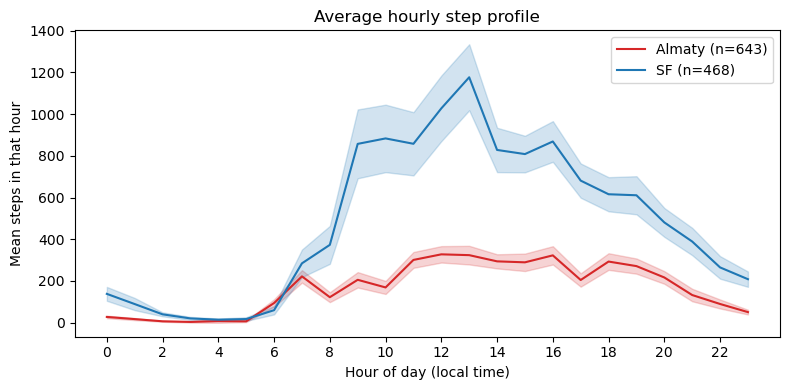

In [15]:
# Create a figure for the graph
fig, ax = plt.subplots(figsize=(8, 4))

# Loop through both cities and assign a color to each
for city, color in [('Almaty', 'tab:red'), ('SF', 'tab:blue')]:

    # Get the hourly step counts for the selected city
    block = df.loc[df['city'] == city, HOUR_COLS].to_numpy(float)

    # Calculate the average steps and standard error for each hour
    mean, sem = block.mean(axis=0), block.std(axis=0) / np.sqrt(len(block))

    # Plot the average number of steps for each hour
    ax.plot(range(24), mean, label=f'{city} (n={len(block)})', color=color)

    # Add a shaded area to show uncertainty around the average
    ax.fill_between(range(24), mean - 2 * sem, mean + 2 * sem, color=color, alpha=0.2)

# Label the x-axis and y-axis
ax.set_xlabel('Hour of day (local time)')
ax.set_ylabel('Mean steps in that hour')

# Add a title and legend, and show every 2 hours on the x-axis
ax.set_title('Average hourly step profile')
ax.legend()
ax.set_xticks(range(0, 24, 2))

# Adjust spacing and display the graph
plt.tight_layout()
plt.show()


## Figure 2: confusion matrix on held-out periods (random forest)

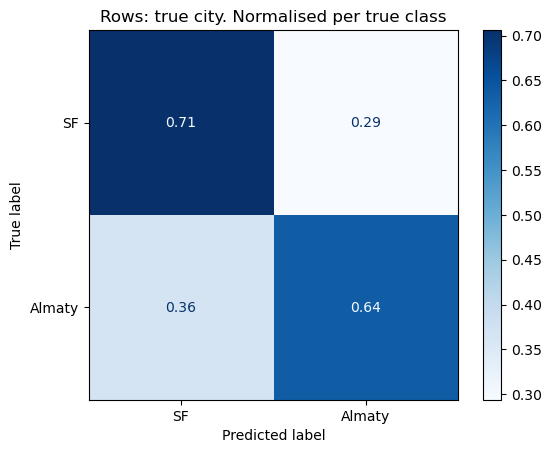

In [16]:
# Get the actual and predicted labels from the random forest model
t, p = pooled['Random forest, hourly counts']

# Create a confusion matrix to compare actual and predicted cities
# Normalize the values to show proportions instead of counts
cm = confusion_matrix(t, p, normalize='true')

# Display the confusion matrix with labels for each city
ConfusionMatrixDisplay(cm, display_labels=['SF', 'Almaty']).plot(
    values_format='.2f', cmap='Blues'
)

plt.title('Rows: true city. Normalised per true class')

plt.show()


## Figure 3: learning curve (random forest, held-out periods)

Balanced accuracy as the number of training days grows.

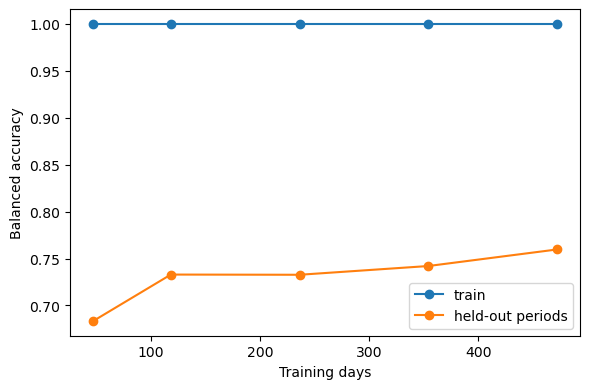

In [17]:
# Test how the model performs with different amounts of training data
sizes, train_scores, test_scores = learning_curve(
    # Create a random forest model with 200 trees
    RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=SEED, n_jobs=-1),

    # Use hourly step counts as features and city labels as targets
    counts, y,

    # Test the model on held-out time periods
    cv=period_splits,

    # Train the model using different percentages of the training data
    train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0],

    # Measure performance using balanced accuracy
    scoring='balanced_accuracy',

    # Shuffle the training data for random selection
    shuffle=True, random_state=SEED
)

# Create a figure for the learning curve
fig, ax = plt.subplots(figsize=(6, 4))

# Plot how well the model performs on training data
ax.plot(sizes, train_scores.mean(axis=1), 'o-', label='train')

# Plot how well the model performs on unseen time periods
ax.plot(sizes, test_scores.mean(axis=1), 'o-', label='held-out periods')

# Label the axes and add a legend
ax.set_xlabel('Training days')
ax.set_ylabel('Balanced accuracy')
ax.legend()

plt.tight_layout()
plt.show()


## Figure 4: which hours matter?

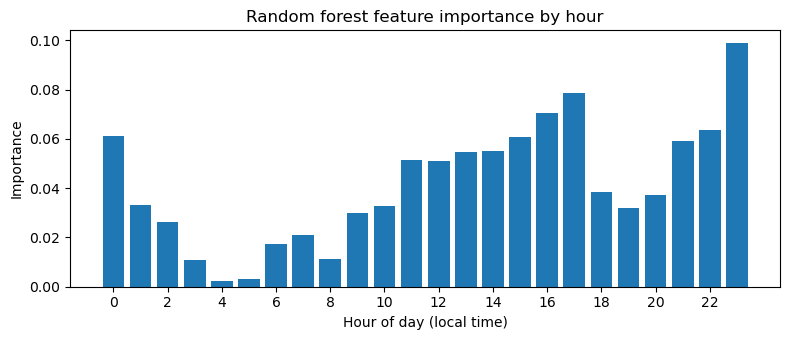

In [18]:
# Train a random forest model using hourly step counts
forest = RandomForestClassifier(
    n_estimators=500,
    class_weight='balanced',
    random_state=SEED,
    n_jobs=-1
).fit(counts, y)

# Create a figure for the bar chart
fig, ax = plt.subplots(figsize=(8, 3.5))

# Show how important each hour is for predicting the city
ax.bar(range(24), forest.feature_importances_)

# Label the x-axis and y-axis
ax.set_xlabel('Hour of day (local time)')
ax.set_ylabel('Importance')

# Show every 2 hours on the x-axis
ax.set_xticks(range(0, 24, 2))

ax.set_title('Random forest feature importance by hour')
plt.tight_layout()
plt.show()


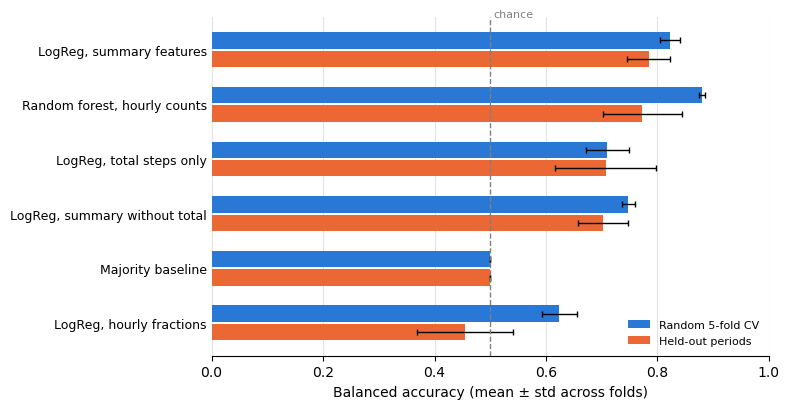

In [19]:
# Builds the model-comparison figure from results_df

# Split score text into mean and standard deviation
def parse_mean_std(text):
    """'0.822 ± 0.018' -> (0.822, 0.018)"""
    mean, std = text.split('±')
    return float(mean), float(std)

# Prepare accuracy scores for plotting
plot_df = results_df.copy()
plot_df[['rand_mean', 'rand_std']] = plot_df['Random CV bal. acc.'].apply(lambda s: pd.Series(parse_mean_std(s)))
plot_df[['held_mean', 'held_std']] = plot_df['Held-out periods bal. acc.'].apply(lambda s: pd.Series(parse_mean_std(s)))

# Sort models by held-out accuracy
plot_df = plot_df.sort_values('held_mean', ascending=True)

# Set bar colors and positions
BLUE, ORANGE = '#2a78d6', '#eb6834'
y = np.arange(len(plot_df))
h = 0.34

# Create the comparison chart
fig, ax = plt.subplots(figsize=(8, 4.2))

# Plot random CV scores with error bars
ax.barh(y + h / 2, plot_df['rand_mean'], h - 0.04, xerr=plot_df['rand_std'],
        color=BLUE, error_kw=dict(ecolor='black', lw=1, capsize=2), label='Random 5-fold CV')

# Plot held-out period scores with error bars
ax.barh(y - h / 2, plot_df['held_mean'], h - 0.04, xerr=plot_df['held_std'],
        color=ORANGE, error_kw=dict(ecolor='black', lw=1, capsize=2), label='Held-out periods')

# Mark chance-level accuracy
ax.axvline(0.5, color='gray', lw=1, ls='--')
ax.text(0.505, len(plot_df) - 0.4, 'chance', fontsize=8, color='gray')

# Set axis labels and limits
ax.set_yticks(y)
ax.set_yticklabels(plot_df.index, fontsize=9)
ax.set_xlim(0, 1.0)
ax.set_xlabel('Balanced accuracy (mean ± std across folds)')

# Style the chart
ax.xaxis.grid(True, color='#e3e2de', lw=0.8)
ax.set_axisbelow(True)
for side in ('top', 'right', 'left'):
    ax.spines[side].set_visible(False)
ax.tick_params(axis='y', length=0)
ax.legend(loc='lower right', fontsize=8, frameon=False)

# Display the chart
plt.tight_layout()
plt.show()
